# CIFAR-10: 작은 CNN의 오류와 신뢰도 분석

PyTorch CNN을 학습하고 혼동 행렬, 오답 이미지, softmax 신뢰도, t-SNE 특징 공간, 5개 시드의 편차를 분석합니다.

이 노트북의 출력은 제공된 원본 실행 결과입니다. 문서 정리 과정에서 학습을 다시 실행하지 않았습니다. 실행 환경은 Colab GPU이며 정확한 패키지 버전은 원본에 기록되어 있지 않습니다.

아래 셀을 순서대로 실행하세요. Colab에서 Drive를 사용하려면 설정을 유지하고, 로컬에서는 USE_DRIVE=False로 설정하세요. 의존성은 같은 폴더의 requirements.txt를 참고하세요.

In [1]:
# ---- 설정 ----
DATA_DIR = "/content/drive/MyDrive/cifar_data"   # 지난번 백업해 둔 위치
USE_DRIVE = True          # Drive 안 쓰면 False (데이터를 새로 받음, 오래 걸림)
SEEDS = [0, 1, 2, 3, 4]   # seed 편차 실험
EPOCHS = 10
BATCH_SIZE = 32
LR = 0.01
TSNE_SAMPLES = 2000

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
else:
    DATA_DIR = "./data"

Mounted at /content/drive


In [2]:
import time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
import torchvision, torchvision.transforms as T

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
CLASSES = ("plane", "car", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")

MEAN, STD = (0.5, 0.5, 0.5), (0.5, 0.5, 0.5)
tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])
trainset = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=tf)
testset = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=tf)
testloader = torch.utils.data.DataLoader(testset, batch_size=256, shuffle=False, num_workers=2)
print(len(trainset), len(testset))

device: cuda


100%|██████████| 170M/170M [57:45<00:00, 49.2kB/s]


50000 10000


## 0. 모델과 학습 함수

합성곱 2개와 완전연결층 3개로 구성된 작은 CNN입니다. 마지막 은닉층의 84차원 특징을 분석에 사용합니다. Python·NumPy·PyTorch의 시드와 학습 데이터 순서를 고정합니다. 결정론적 연산 설정과 환경 버전은 고정하지 않았으므로 다른 환경에서 동일한 수치를 보장하지 않습니다.

In [3]:
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 6, 5); self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(6, 16, 5)
        self.fc1 = nn.Linear(16 * 5 * 5, 120); self.fc2 = nn.Linear(120, 84); self.fc3 = nn.Linear(84, 10)

    def forward(self, x, return_feat=False):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        feat = F.relu(self.fc2(x))          # (B, 84) 특징 벡터
        out = self.fc3(feat)
        return (out, feat) if return_feat else out

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def train(seed, epochs=EPOCHS, bs=BATCH_SIZE, lr=LR, verbose=False):
    set_seed(seed)
    g = torch.Generator().manual_seed(seed)
    loader = torch.utils.data.DataLoader(trainset, batch_size=bs, shuffle=True, num_workers=2, generator=g)
    net = Net().to(device)
    opt = optim.SGD(net.parameters(), lr=lr, momentum=0.9)
    crit = nn.CrossEntropyLoss()
    for ep in range(epochs):
        tot = 0.0
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); loss = crit(net(x), y); loss.backward(); opt.step()
            tot += loss.item()
        if verbose:
            print(f"  seed {seed} epoch {ep+1}: train loss {tot/len(loader):.3f}")
    return net

@torch.no_grad()
def predict(net):
    # 테스트셋 전체의 예측, 확률, 특징, 정답 반환
    net.eval()
    P, Fe, Y = [], [], []
    for x, y in testloader:
        out, feat = net(x.to(device), return_feat=True)
        P.append(F.softmax(out, 1).cpu()); Fe.append(feat.cpu()); Y.append(y)
    return torch.cat(P).numpy(), torch.cat(Fe).numpy(), torch.cat(Y).numpy()

In [4]:
t = time.time()
net = train(seed=0, verbose=True)
probs, feats, y_true = predict(net)
y_pred = probs.argmax(1)
conf = probs.max(1)
print(f"\ntest accuracy: {100*(y_pred==y_true).mean():.1f}%  ({time.time()-t:.0f}s)")

  seed 0 epoch 1: train loss 1.707
  seed 0 epoch 2: train loss 1.335
  seed 0 epoch 3: train loss 1.210
  seed 0 epoch 4: train loss 1.118
  seed 0 epoch 5: train loss 1.052
  seed 0 epoch 6: train loss 0.996
  seed 0 epoch 7: train loss 0.959
  seed 0 epoch 8: train loss 0.924
  seed 0 epoch 9: train loss 0.895
  seed 0 epoch 10: train loss 0.875

test accuracy: 60.6%  (154s)


## 1. Confusion matrix: 무엇과 무엇을 헷갈리는가

행 = 정답, 열 = 예측. 각 행을 100%로 정규화했습니다. 대각선이 클래스별 정확도입니다.

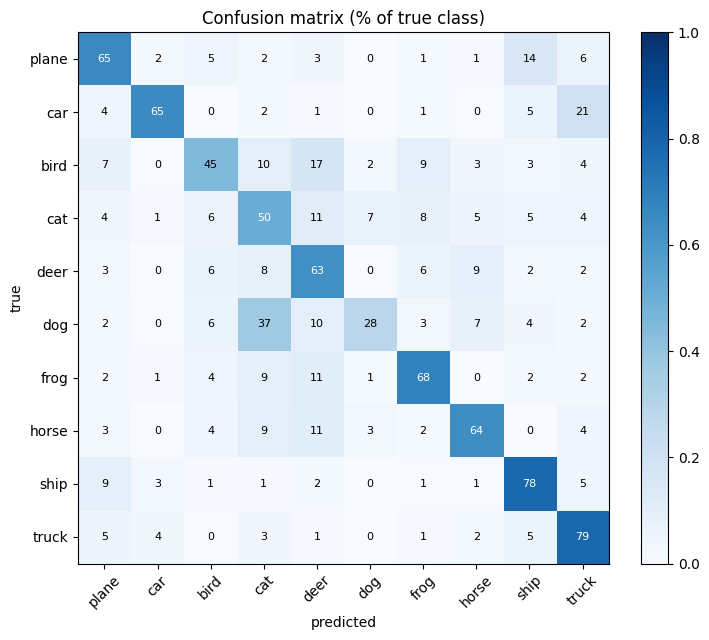

In [5]:
cm = np.zeros((10, 10), dtype=int)
np.add.at(cm, (y_true, y_pred), 1)
cmn = cm / cm.sum(1, keepdims=True)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(10), CLASSES, rotation=45); ax.set_yticks(range(10), CLASSES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{100*cmn[i,j]:.0f}", ha="center", va="center",
                color="white" if cmn[i, j] > 0.5 else "black", fontsize=8)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion matrix (% of true class)")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

In [6]:
# 가장 많이 헷갈린 (정답 → 예측) 쌍 Top 8
pairs = [(CLASSES[i], CLASSES[j], cm[i, j], 100 * cmn[i, j])
         for i in range(10) for j in range(10) if i != j]
top = pd.DataFrame(pairs, columns=["true", "predicted", "count", "% of true"]) \
        .sort_values("count", ascending=False).head(8).reset_index(drop=True)
top.round(1)

,true,predicted,count,% of true
0,dog,cat,370,37.0
1,car,truck,208,20.8
2,bird,deer,168,16.8
3,plane,ship,142,14.2
4,cat,deer,110,11.0
5,horse,deer,108,10.8
6,frog,deer,108,10.8
7,dog,deer,100,10.0


## 2. 오답 사례 보기: 고양이는 무엇으로 오인되는가

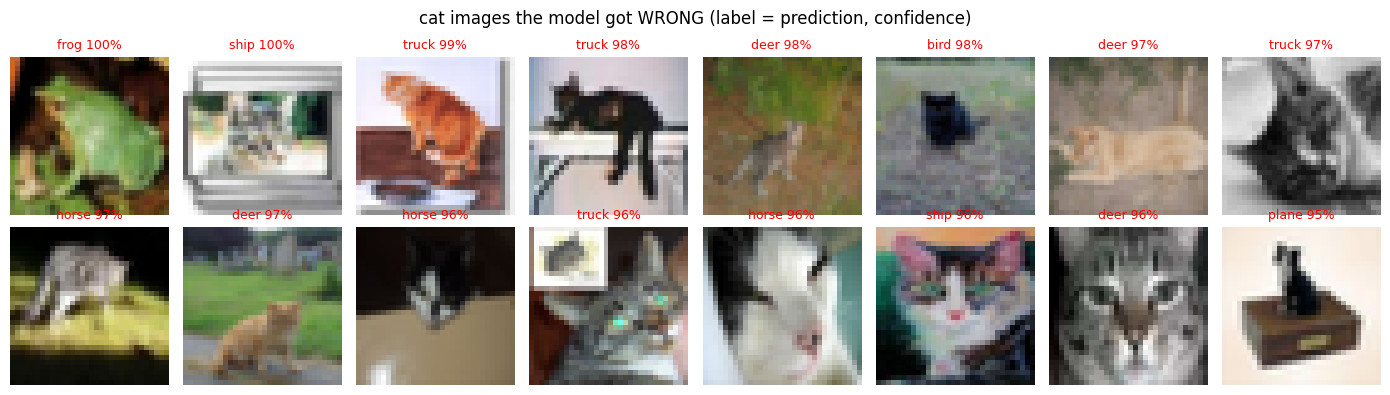

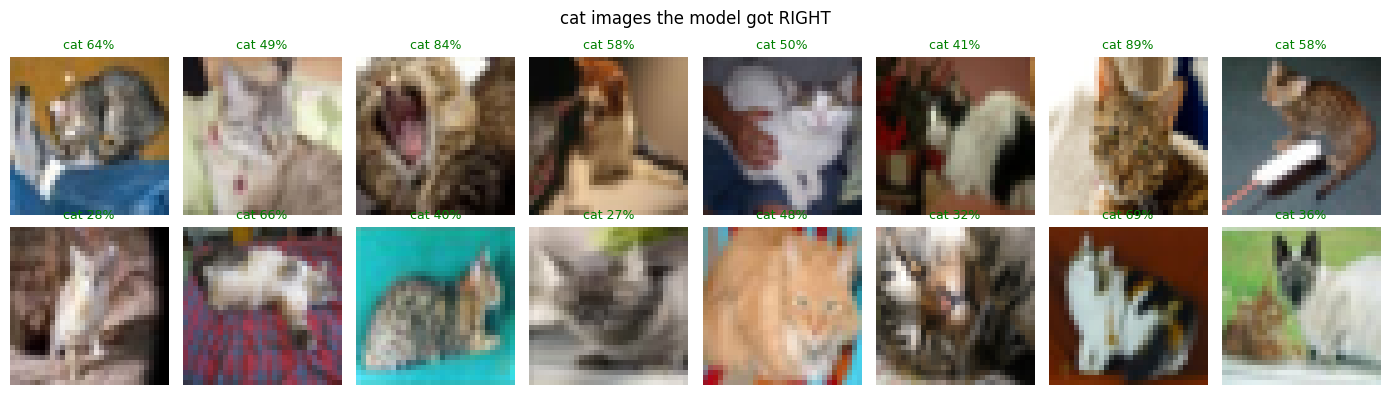

In [7]:
def show(idx, title, n=16):
    idx = idx[:n]
    fig, axes = plt.subplots(2, 8, figsize=(14, 4))
    for ax, i in zip(axes.flat, idx):
        img = testset[i][0].numpy().transpose(1, 2, 0) * np.array(STD) + np.array(MEAN)
        ax.imshow(np.clip(img, 0, 1))
        ax.set_title(f"{CLASSES[y_pred[i]]} {100*conf[i]:.0f}%", fontsize=9,
                     color="green" if y_pred[i] == y_true[i] else "red")
        ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.show()

TARGET = CLASSES.index("cat")
wrong_cat = np.where((y_true == TARGET) & (y_pred != TARGET))[0]
wrong_cat = wrong_cat[np.argsort(-conf[wrong_cat])]          # 확신하며 틀린 순
show(wrong_cat, "cat images the model got WRONG (label = prediction, confidence)")
right_cat = np.where((y_true == TARGET) & (y_pred == TARGET))[0]
show(right_cat, "cat images the model got RIGHT")

## 3. 신뢰도 분석

최대 softmax 값을 신뢰도 점수로 사용합니다. 이 값이 실제 정답 확률과 일치하는지는 별도로 확인해야 합니다.

Reliability diagram은 10개 구간의 정확도를 구간 중앙에 표시합니다. ECE 계산에는 각 구간의 실제 평균 신뢰도와 정확도를 사용합니다. 따라서 그림의 구간 중앙과 평균 신뢰도는 다를 수 있습니다.

낮은 신뢰도의 예측을 거르는 것은 정확도와 coverage의 관계를 탐색하는 분석입니다. 테스트셋에서 확인한 임계값을 검증 없이 배포 기준으로 선택하지 않습니다.

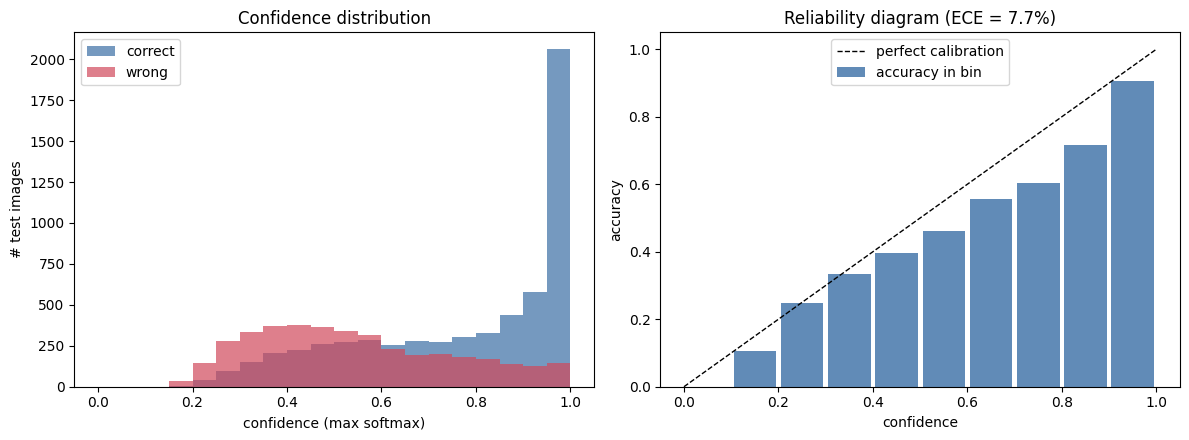

맞힌 예측 평균 확신도 0.78 / 틀린 예측 평균 확신도 0.54
확신도 >= 0.9 인 예측 2916개 중 틀린 비율: 9.4%


In [8]:
correct = y_pred == y_true
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(conf[correct], bins=20, range=(0, 1), alpha=.7, label="correct", color="#3a6ea5")
axes[0].hist(conf[~correct], bins=20, range=(0, 1), alpha=.7, label="wrong", color="#d1495b")
axes[0].set_xlabel("confidence (max softmax)"); axes[0].set_ylabel("# test images")
axes[0].set_title("Confidence distribution"); axes[0].legend()

bins = np.linspace(0, 1, 11)
ids = np.clip(np.digitize(conf, bins) - 1, 0, 9)
acc_b = np.array([correct[ids == b].mean() if (ids == b).any() else np.nan for b in range(10)])
conf_b = np.array([conf[ids == b].mean() if (ids == b).any() else np.nan for b in range(10)])
cnt_b = np.bincount(ids, minlength=10)
ece = np.nansum(cnt_b / len(conf) * np.abs(acc_b - conf_b))   # Expected Calibration Error

axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
axes[1].bar(bins[:-1] + .05, acc_b, width=.09, color="#3a6ea5", alpha=.8, label="accuracy in bin")
axes[1].set_xlabel("confidence"); axes[1].set_ylabel("accuracy")
axes[1].set_title(f"Reliability diagram (ECE = {100*ece:.1f}%)"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"맞힌 예측 평균 확신도 {conf[correct].mean():.2f} / 틀린 예측 평균 확신도 {conf[~correct].mean():.2f}")
hi = conf >= .9
if hi.any():
    print(f"확신도 >= 0.9 인 예측 {hi.sum()}개 중 틀린 비율: {100*(~correct[hi]).mean():.1f}%")
else:
    print("확신도 >= 0.9 인 예측이 없습니다.")

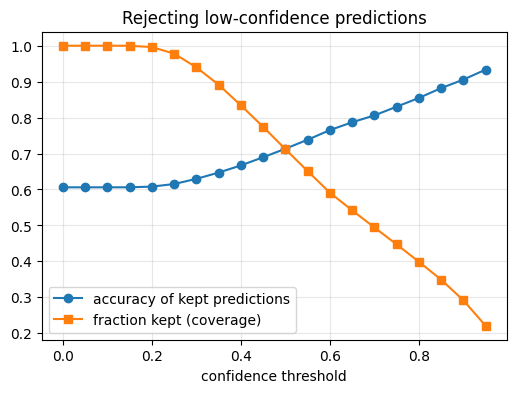

In [9]:
# 확신도 임계값을 올리면: 남는 예측의 정확도 vs 버려지는 비율 (위치추정의 '관측 거부'와 같은 개념)
th = np.linspace(0, .95, 20)
cov = [(conf >= t).mean() for t in th]
acc = [correct[conf >= t].mean() if (conf >= t).any() else np.nan for t in th]
plt.figure(figsize=(6, 4))
plt.plot(th, acc, "o-", label="accuracy of kept predictions")
plt.plot(th, cov, "s-", label="fraction kept (coverage)")
plt.xlabel("confidence threshold"); plt.grid(alpha=.3); plt.legend()
plt.title("Rejecting low-confidence predictions"); plt.show()

## 4. 특징 공간 시각화

84차원 특징 중 무작위 2,000개를 t-SNE로 2차원에 투영합니다. 클래스 혼동에 대한 탐색 자료로 사용합니다. 투영은 거리와 군집 구조를 왜곡할 수 있으므로 군집의 위치나 겹침만으로 성능 또는 혼동 원인을 입증할 수 없습니다.

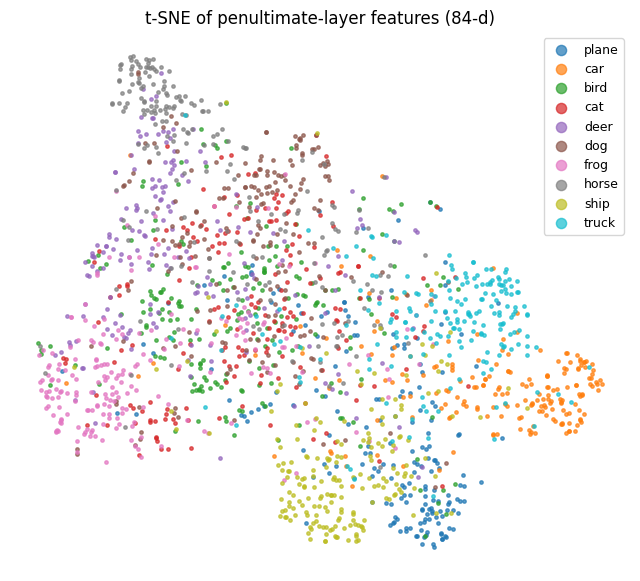

In [10]:
from sklearn.manifold import TSNE
rng = np.random.default_rng(0)
sel = rng.choice(len(feats), size=min(TSNE_SAMPLES, len(feats)), replace=False)
emb = TSNE(n_components=2, init="pca", perplexity=30, random_state=0).fit_transform(feats[sel])

plt.figure(figsize=(8, 7))
cmap = plt.get_cmap("tab10")
for c in range(10):
    m = y_true[sel] == c
    plt.scatter(emb[m, 0], emb[m, 1], s=6, color=cmap(c), label=CLASSES[c], alpha=.7)
plt.legend(markerscale=3, fontsize=9, loc="best"); plt.axis("off")
plt.title("t-SNE of penultimate-layer features (84-d)"); plt.show()

## 5. 시드별 편차

같은 설정에서 시드 0~4를 비교합니다. 표와 오차 막대는 평균과 표본 표준편차(ddof=1)입니다. 신뢰구간이나 통계적 유의성 검정 결과가 아닙니다.

seed 0은 이미 학습한 모델을 재사용하므로 아래 시간에는 평가만 포함됩니다. 다른 시드의 시간에는 학습과 평가가 포함되어 직접적인 속도 비교 대상이 아닙니다.

In [11]:
results = []
for s in SEEDS:
    t = time.time()
    n = net if s == 0 else train(seed=s)        # seed 0은 위에서 이미 학습
    p, _, y = predict(n)
    pred = p.argmax(1)
    row = {"seed": s, "overall": 100 * (pred == y).mean()}
    row.update({c: 100 * (pred[y == i] == i).mean() for i, c in enumerate(CLASSES)})
    results.append(row)
    print(f"seed {s}: {row['overall']:.1f}%  ({time.time()-t:.0f}s)")

res = pd.DataFrame(results).set_index("seed")
summary = res.agg(["mean", "std", "min", "max"]).T.round(1)
summary

seed 0: 60.6%  (2s)
seed 1: 62.1%  (152s)
seed 2: 61.6%  (152s)
seed 3: 61.5%  (153s)
seed 4: 61.7%  (153s)


,mean,std,min,max
overall,61.5,0.6,60.6,62.1
plane,61.9,4.9,53.8,65.9
car,71.1,6.2,64.6,78.9
bird,48.3,4.3,43.3,53.9
cat,41.7,9.5,25.7,50.4
deer,59.8,7.9,53.0,72.1
dog,47.5,12.1,28.4,62.2
frog,73.0,4.7,67.5,77.3
horse,63.6,3.5,59.0,67.5
ship,74.6,4.8,69.3,80.7


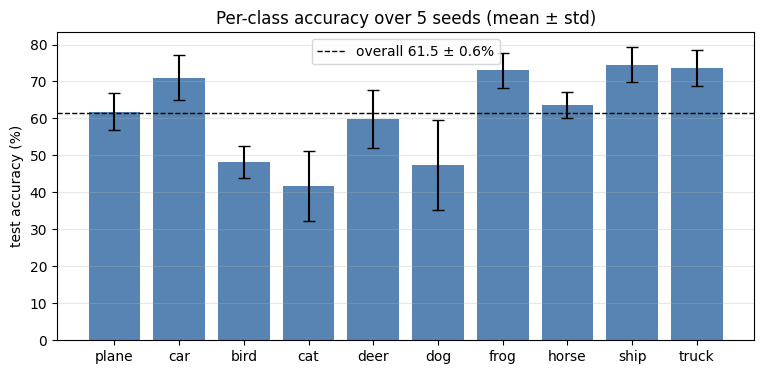

In [12]:
m, sd = res[list(CLASSES)].mean(), res[list(CLASSES)].std()
plt.figure(figsize=(9, 4))
plt.bar(CLASSES, m, yerr=sd, capsize=4, color="#3a6ea5", alpha=.85)
plt.axhline(res["overall"].mean(), color="k", ls="--", lw=1, label=f"overall {res['overall'].mean():.1f} ± {res['overall'].std():.1f}%")
plt.ylabel("test accuracy (%)"); plt.title(f"Per-class accuracy over {len(SEEDS)} seeds (mean ± std)")
plt.legend(); plt.grid(axis="y", alpha=.3); plt.show()

## 6. 관찰, 한계, 다음 실험

- 5개 시드의 테스트 정확도는 **61.5 ± 0.6%**(평균 ± 표본 표준편차), 범위는 60.6~62.1%입니다.
- dog의 클래스별 정확도는 47.5 ± 12.1%, cat은 41.7 ± 9.5%로 전체 정확도보다 편차가 큽니다.
- seed 0의 가장 큰 혼동은 dog → cat: 370개, 정답 dog의 37.0%입니다. car → truck은 20.8%, bird → deer는 16.8%입니다.
- seed 0의 정답/오답 평균 신뢰도는 각각 0.78/0.54입니다. 신뢰도 0.9 이상인 2,916개에서도 9.4%가 오답입니다. 높은 점수도 정답을 보장하지 않습니다.
- 배경·색상 의존은 오답 이미지에서 얻은 **가설**입니다. 배경 제거 또는 통제 실험 없이 원인으로 확정할 수 없습니다.
- t-SNE는 탐색적 시각화이며 정량 평가를 대체하지 않습니다.

기존 2-epoch 실험과는 epoch·batch size·학습률 등 여러 조건이 달라 특정 변경의 효과나 통계적 유의성을 주장하지 않습니다. 현재 결과는 테스트셋을 사용한 사후 분석입니다.

다음 단계: 학습셋에서 별도 검증셋을 분리하고, 데이터 증강·모델 크기·temperature scaling을 각각 통제 실험합니다. 임계값과 보정 파라미터는 검증셋에서 선택하고 최종 테스트 평가를 별도로 수행합니다. 환경 버전과 체크포인트도 저장할 계획입니다.

### 위치추정에 대한 관심

관측 신뢰도와 오류를 함께 살펴본다는 개념은 위치추정에도 연결할 수 있습니다. 이 프로젝트에서는 particle filter, 로봇 위치추정 또는 관측 likelihood 모델을 구현하거나 검증하지 않았습니다.